# 7. Test-period evaluation

Point accuracy, Diebold-Mariano tests, accuracy by horizon and interval coverage.

In [1]:
import sys
from pathlib import Path
CODE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_DIR))
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from src import config, experiment
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
TABLES = config.OUTPUT_DIR / "tables"
FIGS = config.FIGURE_DIR

In [2]:
for name in ['m5', 'rossmann']:
    display(Markdown(f'**{name}: test summary**'))
    display(pd.read_csv(TABLES / f'{name}_test_summary.csv').round(4))

**m5: test summary**

,model,rmse,mae,mape,mase,coverage,width_scaled,winkler_scaled,coverage_native,width_native,winkler_native,mase_sd_seeds,n_seeds
0,snaive,620.2852,467.4627,11.9176,1.1960,0.9399,7.3366,10.4834,NaN,NaN,NaN,0.0000,1
1,arima,419.0360,311.0204,7.8654,0.8379,0.9358,4.8173,7.2612,0.9084,3.6828,6.8579,0.0000,1
2,ets,530.9900,406.9646,10.3041,1.0368,0.9261,5.1624,8.0959,0.9402,5.4116,7.9296,0.0000,1
3,ffnn,417.0184,312.2168,7.7707,0.8637,0.9285,4.7151,7.4887,NaN,NaN,NaN,0.0176,5
4,lstm,496.7167,379.5762,9.2202,1.0814,0.9030,5.7022,10.6727,NaN,NaN,NaN,0.0353,5
5,hyb_d,397.6771,295.8313,7.4842,0.7979,0.9358,4.4165,6.8926,NaN,NaN,NaN,0.0050,5
6,hyb_ms,412.9333,308.7850,7.7056,0.8472,0.9288,4.8493,7.4754,NaN,NaN,NaN,0.0226,5
7,hyb_z,371.2966,276.4836,6.9961,0.7458,0.9426,4.3394,6.4063,NaN,NaN,NaN,0.0085,5


**rossmann: test summary**

,model,rmse,mae,mape,mase,coverage,width_scaled,winkler_scaled,coverage_native,width_native,winkler_native,mase_sd_seeds,n_seeds
0,snaive,2209.2101,1647.8357,23.9788,0.7673,0.9387,4.5640,5.8787,NaN,NaN,NaN,0.0000,1
1,arima,1027.4673,758.8185,10.7770,0.3588,0.9571,2.6405,3.4286,0.9670,2.1526,2.7007,0.0000,1
2,ets,1962.9778,1545.7316,22.1822,0.7251,0.9257,4.3167,5.8458,0.9892,6.3609,6.4627,0.0000,1
3,ffnn,907.8543,689.2356,9.9338,0.3279,0.9606,2.3156,2.8783,NaN,NaN,NaN,0.0054,5
4,lstm,991.8751,765.8572,11.2857,0.3635,0.9629,2.4735,3.1084,NaN,NaN,NaN,0.0094,5
5,hyb_d,1006.4089,744.0525,10.6395,0.3520,0.9496,2.4209,3.3389,NaN,NaN,NaN,0.0025,5
6,hyb_ms,908.2359,674.5361,9.6409,0.3202,0.9400,2.0697,2.9932,NaN,NaN,NaN,0.0034,5
7,hyb_z,972.1635,710.9340,10.1453,0.3369,0.9453,2.2986,3.2908,NaN,NaN,NaN,0.0059,5


In [3]:
for name in ['m5', 'rossmann']:
    display(Markdown(f'**{name}: Diebold-Mariano tests**'))
    display(pd.read_csv(TABLES / f'{name}_dm_tests.csv').round(4))

**m5: Diebold-Mariano tests**

,comparison,other,loss,n_days,mean_loss_diff_seed1,dm_stat_seed1,p_value_seed1,p_holm_seed1,median_p_over_seeds,median_p_holm_over_seeds,seeds_hybrid_better_holm05,seeds_hybrid_worse_holm05,seeds_hybrid_better_p05,seeds_hybrid_worse_p05,n_seeds,series_hybrid_better_p05_seed1,series_hybrid_worse_p05_seed1,variance_method_seed1
0,hyb_z vs snaive,snaive,absolute,391,0.4392,7.8687,0.0000,0.0000,0.0000,0.0000,5,0,5,0,5,9,0,rectangular
1,hyb_z vs snaive,snaive,squared,391,1.5477,5.5867,0.0000,0.0000,0.0000,0.0000,5,0,5,0,5,10,0,rectangular
2,hyb_z vs arima,arima,absolute,391,0.0811,3.3981,0.0007,0.0015,0.0000,0.0000,5,0,5,0,5,7,0,rectangular
3,hyb_z vs arima,arima,squared,391,0.2642,3.2506,0.0013,0.0025,0.0001,0.0003,5,0,5,0,5,8,0,rectangular
4,hyb_z vs ets,ets,absolute,391,0.2800,6.6124,0.0000,0.0000,0.0000,0.0000,5,0,5,0,5,10,0,rectangular
5,hyb_z vs ets,ets,squared,391,0.7942,5.4156,0.0000,0.0000,0.0000,0.0000,5,0,5,0,5,10,0,rectangular
6,hyb_z vs ffnn,ffnn,absolute,391,0.1245,5.1065,0.0000,0.0000,0.0000,0.0000,5,0,5,0,5,7,0,rectangular
7,hyb_z vs ffnn,ffnn,squared,391,0.3818,5.3550,0.0000,0.0000,0.0000,0.0000,5,0,5,0,5,8,0,rectangular
8,hyb_z vs lstm,lstm,absolute,391,0.3001,5.1539,0.0000,0.0000,0.0000,0.0000,5,0,5,0,5,8,0,rectangular
9,hyb_z vs lstm,lstm,squared,391,1.2853,4.1641,0.0000,0.0002,0.0000,0.0002,5,0,5,0,5,9,0,rectangular


**rossmann: Diebold-Mariano tests**

,comparison,other,loss,n_days,mean_loss_diff_seed1,dm_stat_seed1,p_value_seed1,p_holm_seed1,median_p_over_seeds,median_p_holm_over_seeds,seeds_hybrid_better_holm05,seeds_hybrid_worse_holm05,seeds_hybrid_better_p05,seeds_hybrid_worse_p05,n_seeds,series_hybrid_better_p05_seed1,series_hybrid_worse_p05_seed1,variance_method_seed1
0,hyb_ms vs snaive,snaive,absolute,163,0.4415,5.9787,0.0000,0.0000,0.0000,0.0000,5,0,5,0,5,20,0,rectangular
1,hyb_ms vs snaive,snaive,squared,163,0.8611,4.4631,0.0000,0.0001,0.0000,0.0001,5,0,5,0,5,20,0,rectangular
2,hyb_ms vs arima,arima,absolute,163,0.0351,1.8341,0.0685,0.2739,0.0055,0.0274,3,0,4,0,5,8,0,bartlett
3,hyb_ms vs arima,arima,squared,163,0.0476,5.7688,0.0000,0.0000,0.0089,0.0443,3,0,4,0,5,10,0,rectangular
4,hyb_ms vs ets,ets,absolute,163,0.3996,7.1966,0.0000,0.0000,0.0000,0.0000,5,0,5,0,5,20,0,rectangular
5,hyb_ms vs ets,ets,squared,163,0.6579,4.2955,0.0000,0.0001,0.0000,0.0001,5,0,5,0,5,19,0,rectangular
6,hyb_ms vs ffnn,ffnn,absolute,163,0.0028,0.2332,0.8159,1.0000,0.7110,0.7110,0,0,0,0,5,3,2,rectangular
7,hyb_ms vs ffnn,ffnn,squared,163,-0.0060,-0.3035,0.7619,0.7619,0.7619,0.7619,0,0,0,0,5,0,2,rectangular
8,hyb_ms vs lstm,lstm,absolute,163,0.0336,1.4737,0.1425,0.4275,0.0619,0.1858,1,0,2,0,5,3,0,rectangular
9,hyb_ms vs lstm,lstm,squared,163,0.0335,1.0397,0.3000,0.6000,0.1300,0.3469,1,0,1,0,5,2,0,rectangular


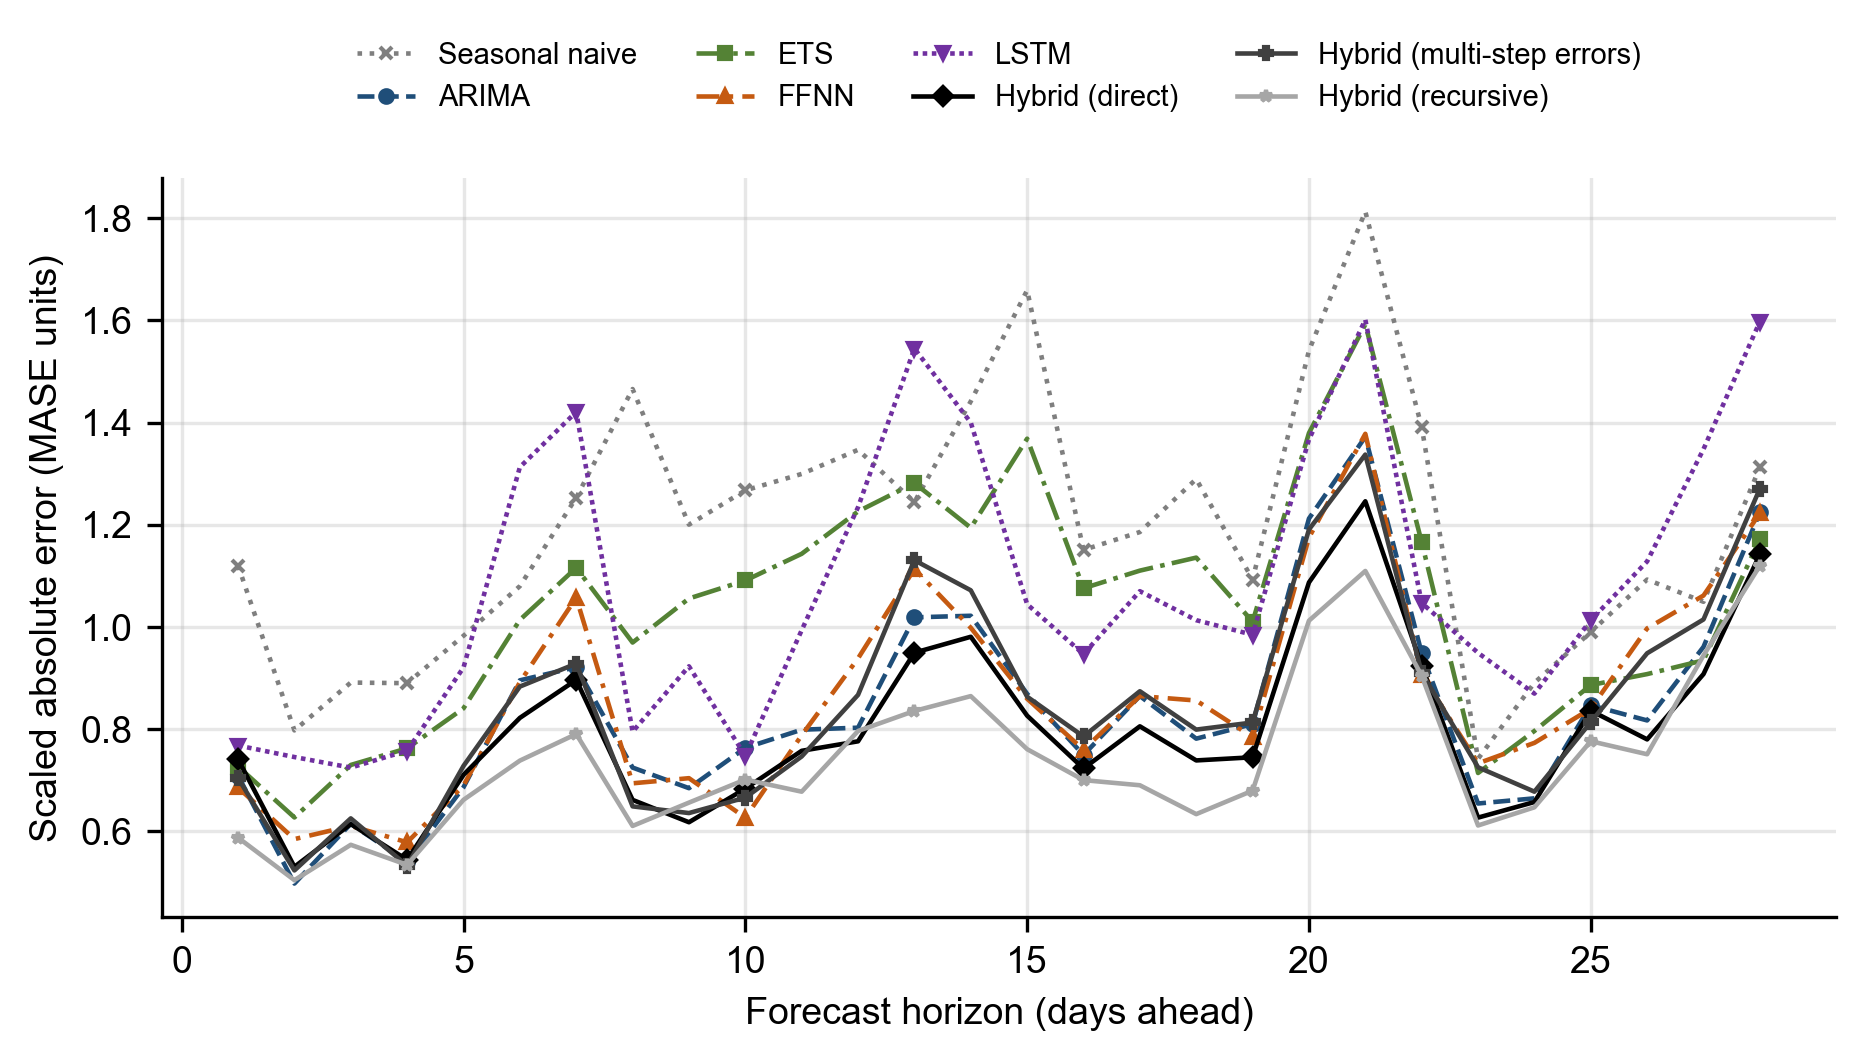

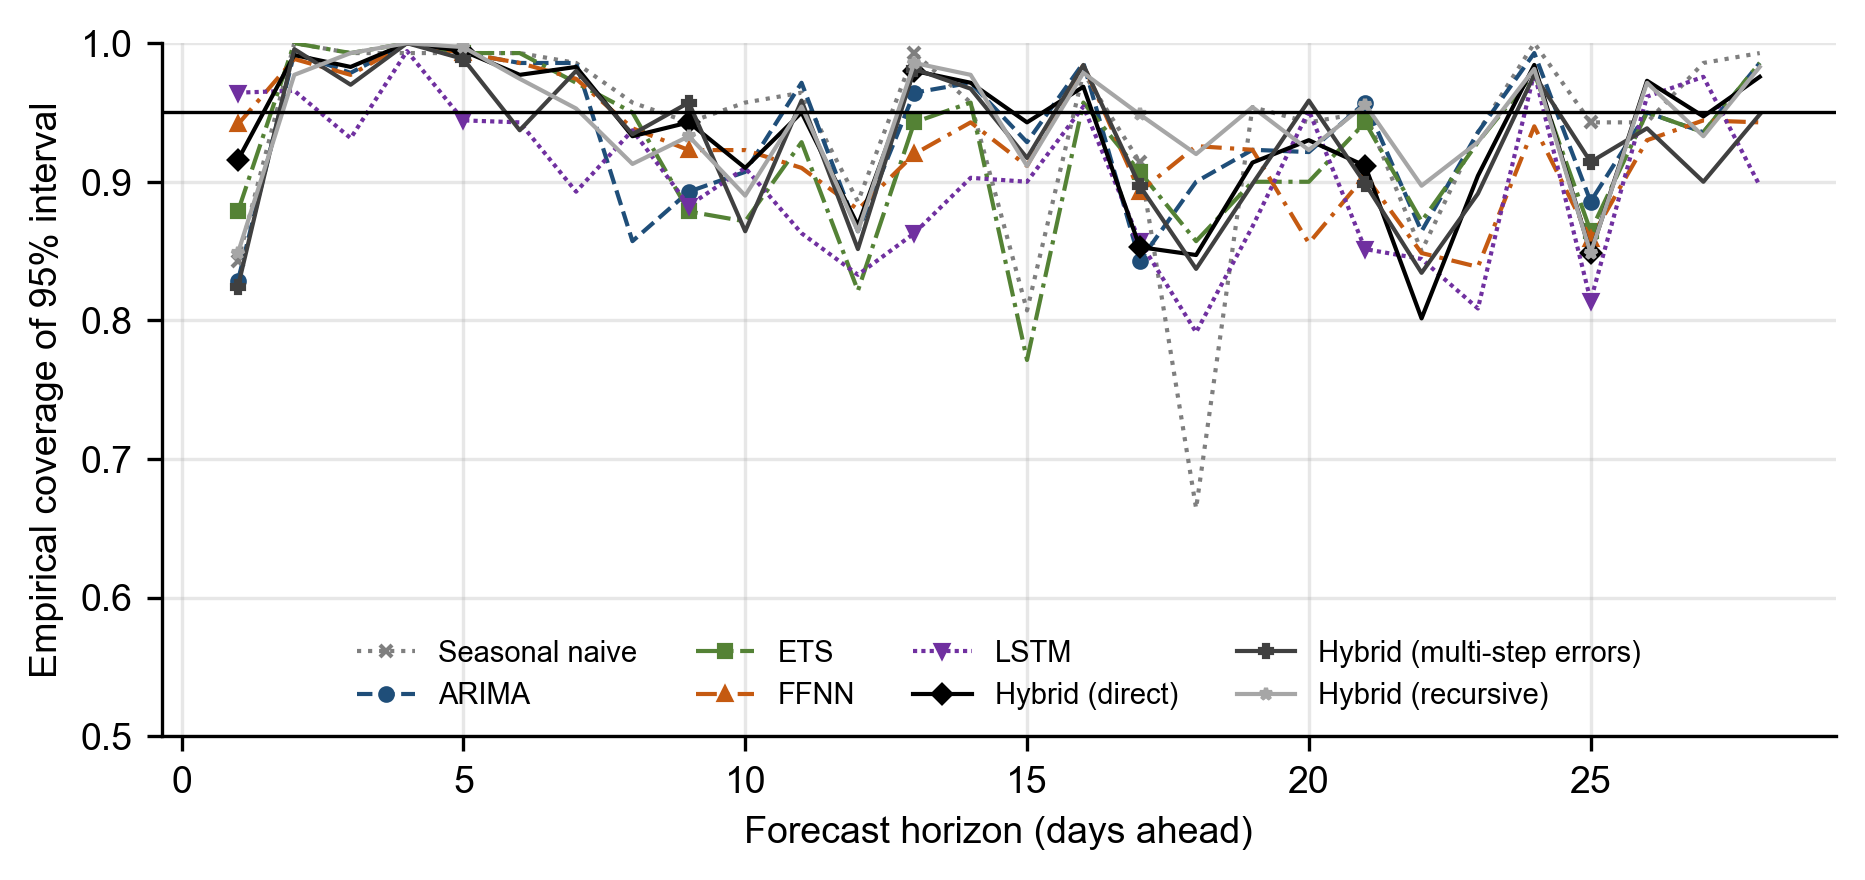

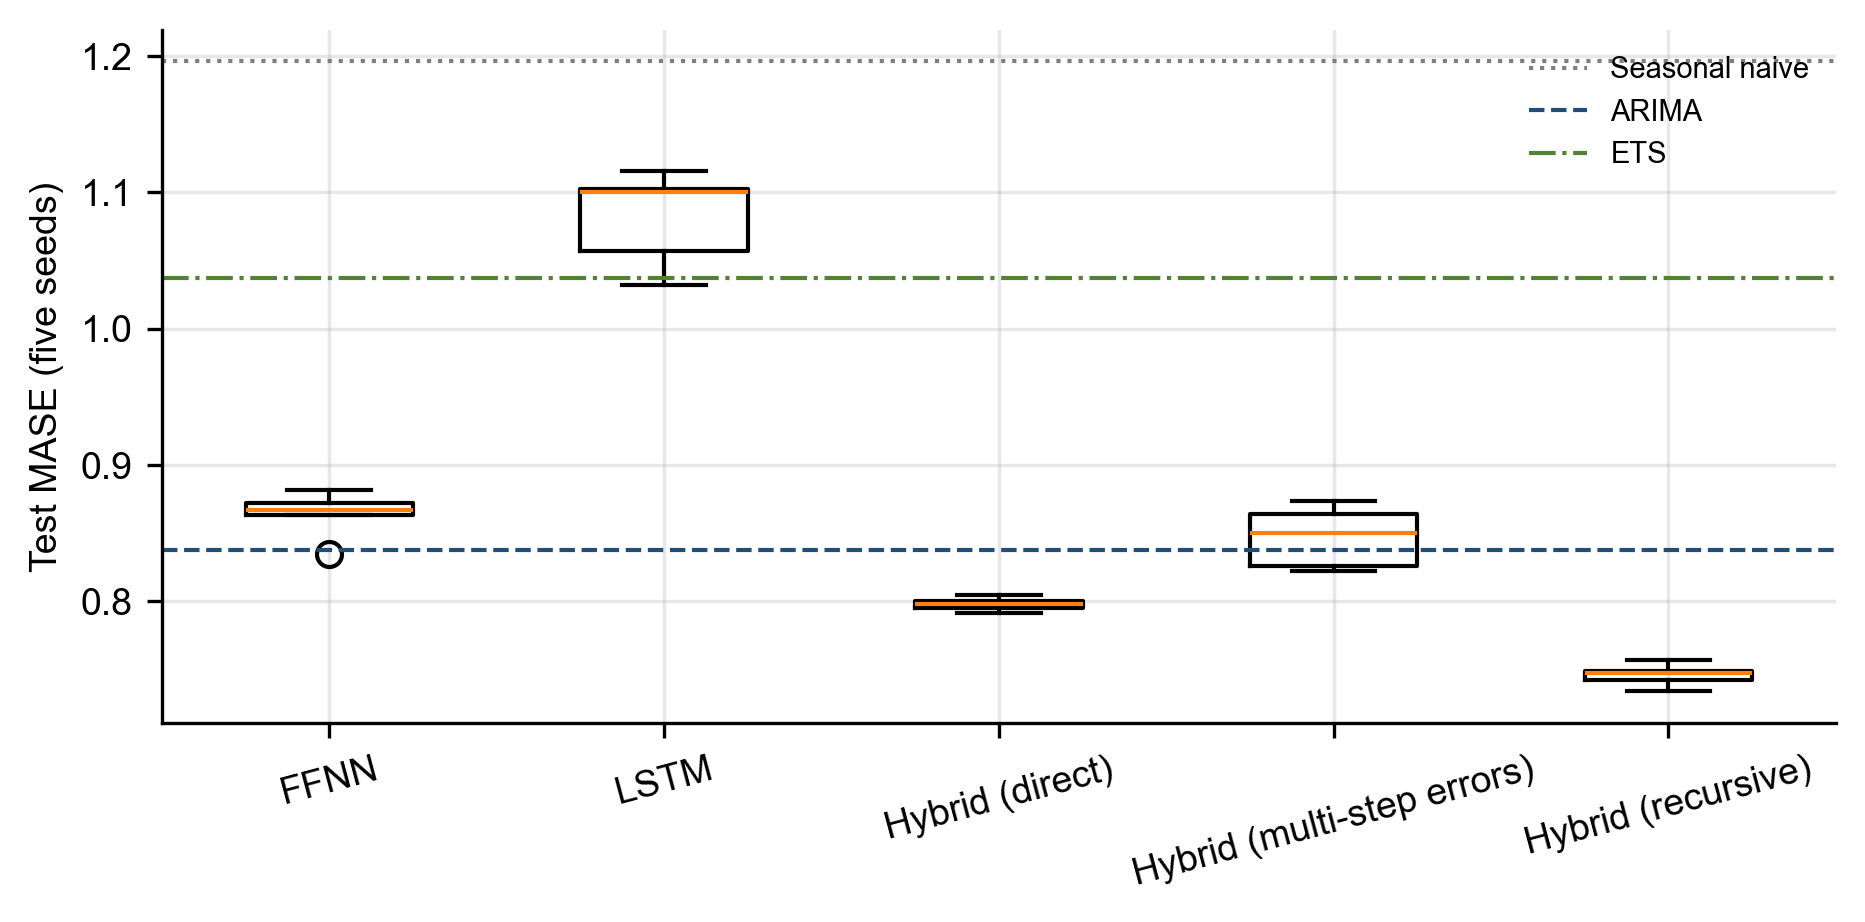

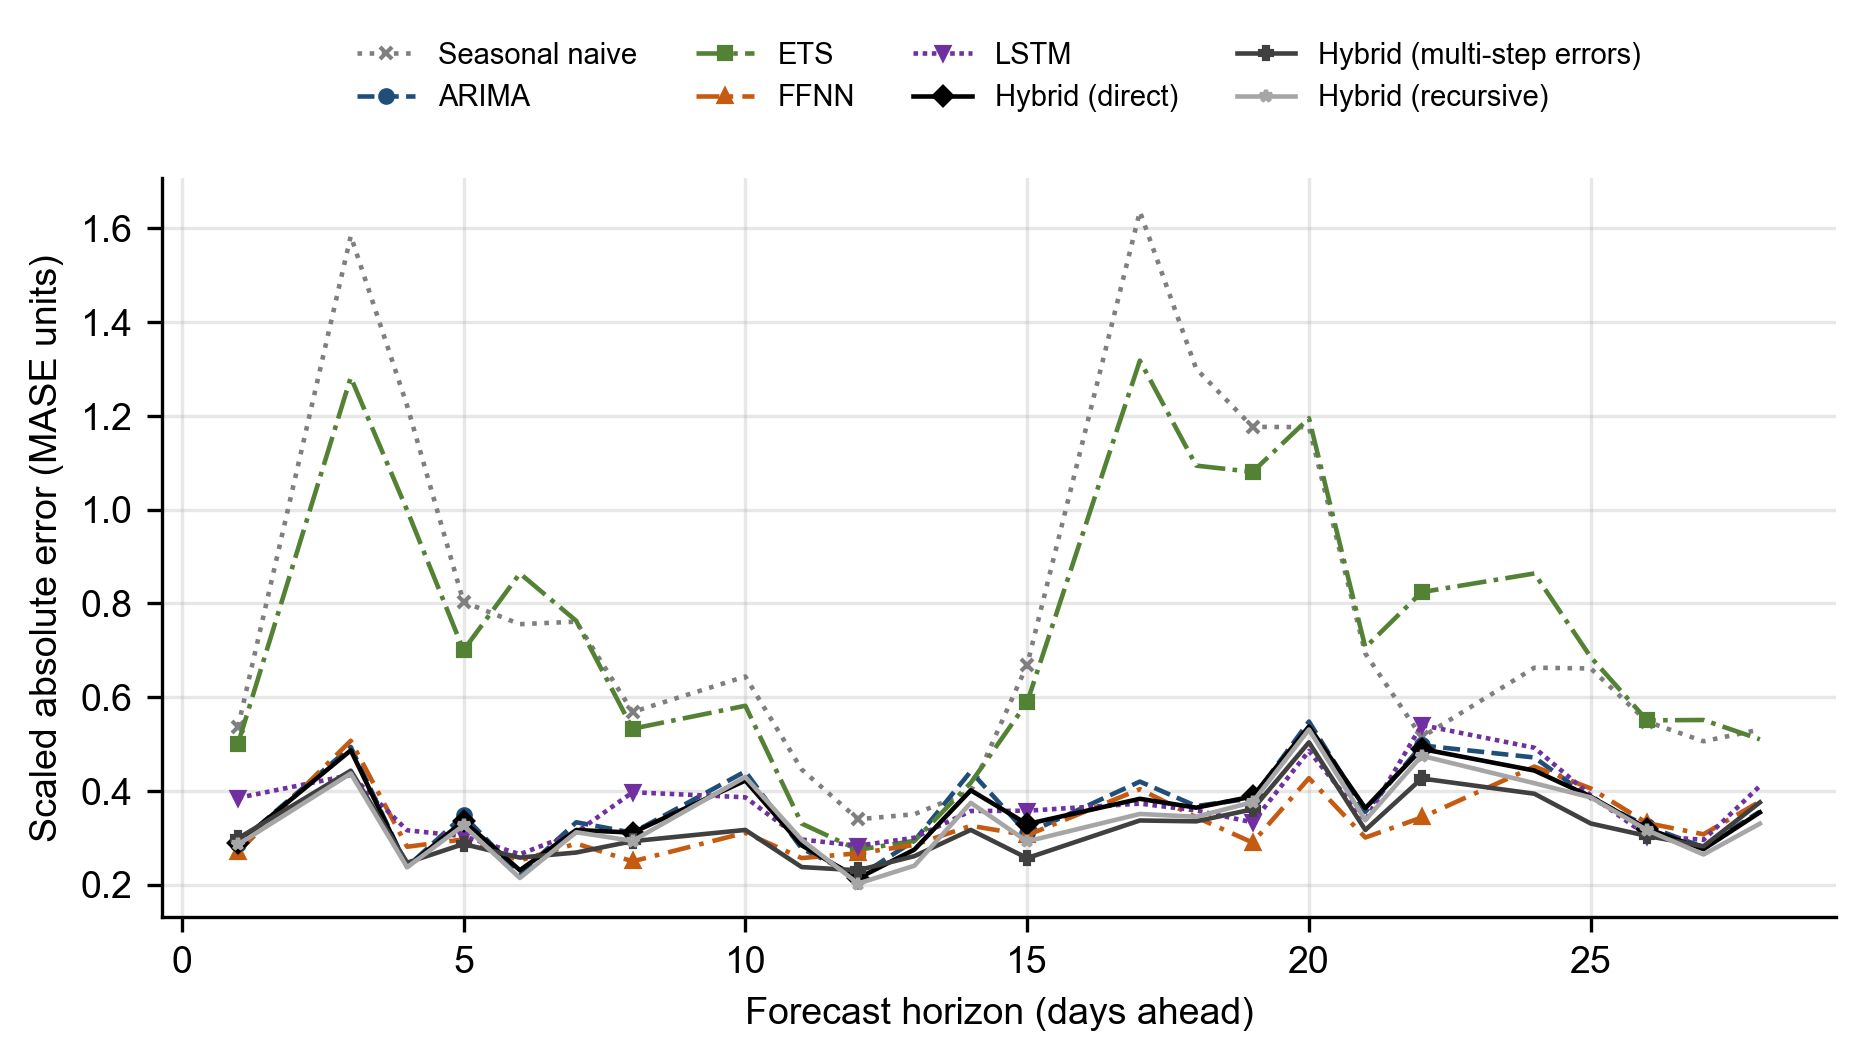

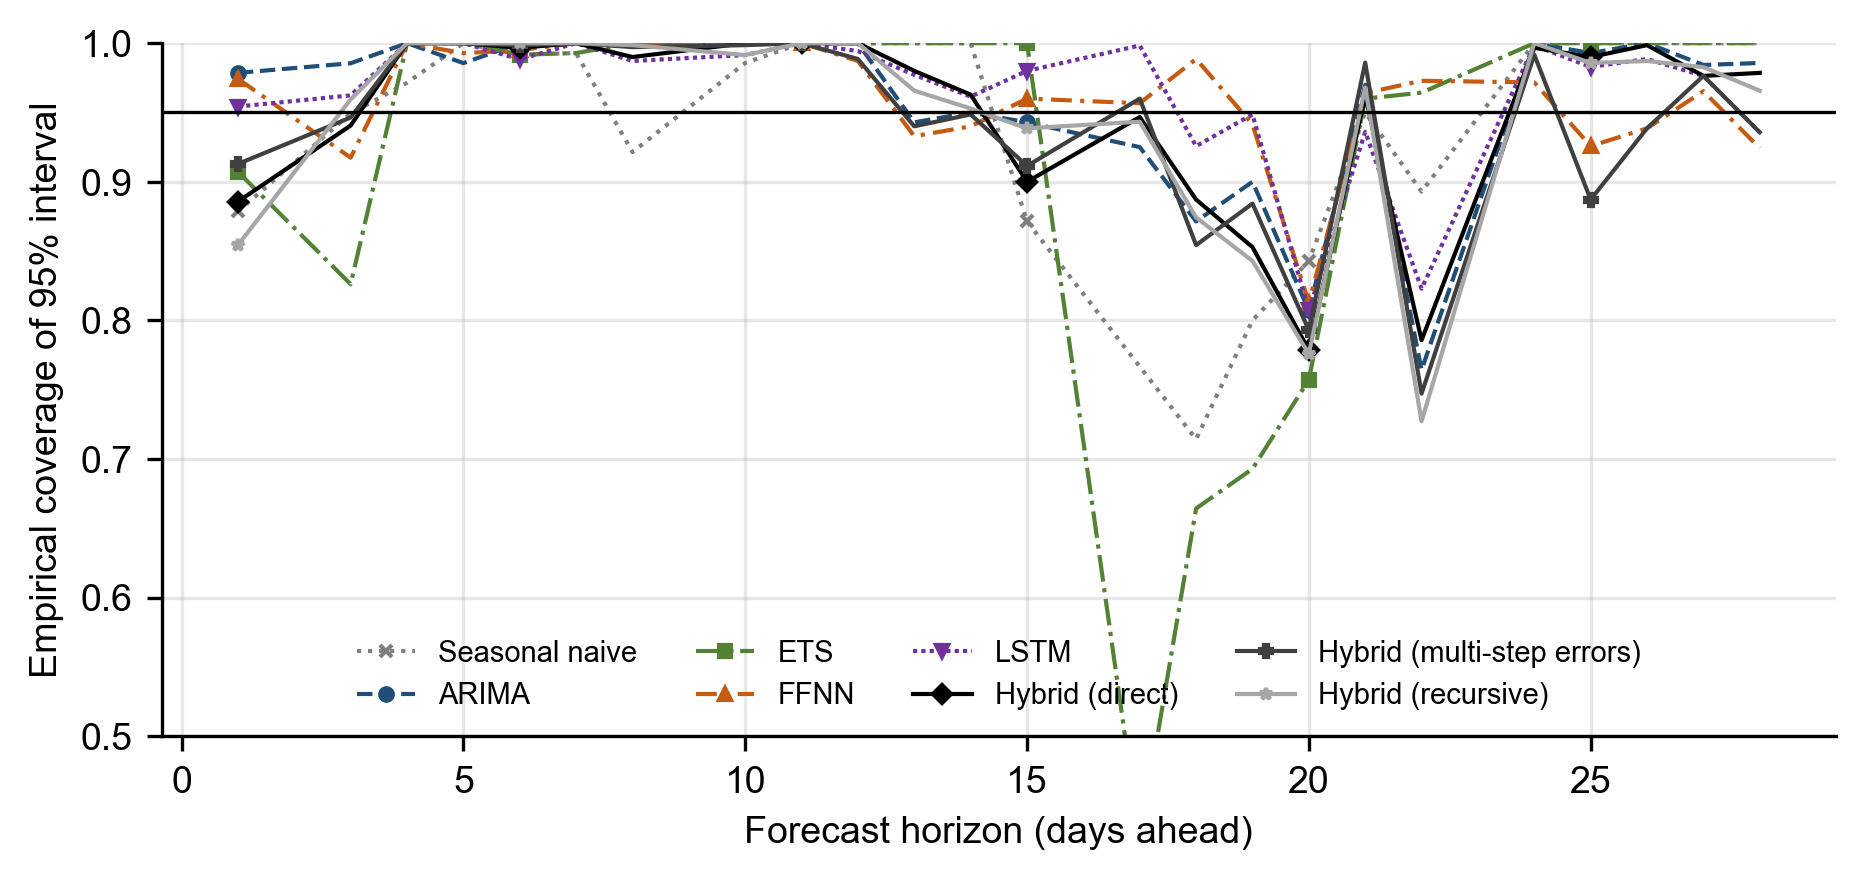

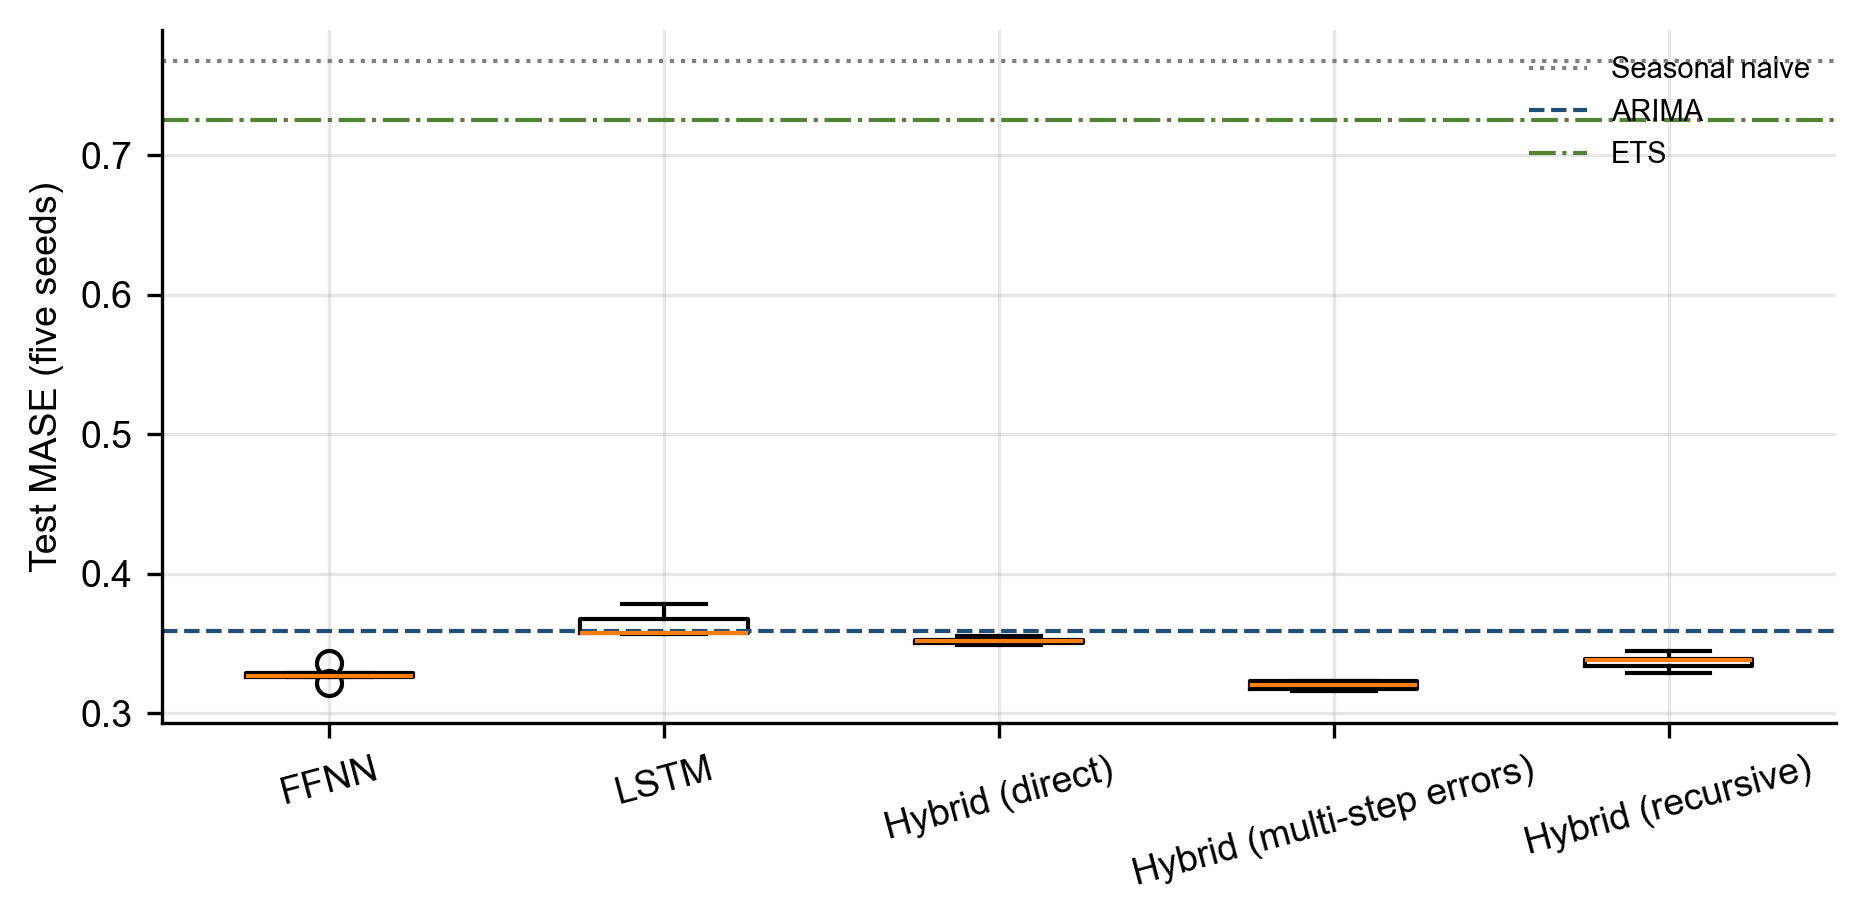

In [4]:
for name in ['m5', 'rossmann']:
    for fig in ['mase_by_horizon', 'coverage_by_horizon', 'seed_stability']:
        display(Image(filename=str(FIGS / f'res_{name}_{fig}.png'), width=800))